# Step 1: Crop and Average Videos

First step of the cell delamination video analysis pipeline. Processes TIFF microscopy videos by:
1. Uploading and converting each video to a pixel brightness DataFrame
2. Cropping to a user-defined region of interest
3. Subdividing into cell-sized quadrants and averaging pixel brightness over time
4. Saving results as Excel files for use in Step 2

## Requirements
```
pip install numpy pandas matplotlib opencv-python tifffile openpyxl
```
Or use the provided `Cell2spec_anaconda_environment.yaml`:
```
conda env create -f Cell2spec_anaconda_environment.yaml
```

## How to use
1. Update the **Configuration** cell with your video folder path, experiment date, and video names
2. Set `cell_size`, `x`, `y`, `w`, `h` in the High Level Analysis cell to match your experiment
3. Run all cells sequentially

> **Note:** Documentation was generated with AI assistance.


## Import Libraries
Don't touch this, it will mess with dependencies (it needs to be run every time before you run the code)

In [14]:
import numpy as np
import pandas as pd
import os                                           #operating system: to import and save files directly to downloads folder
import tifffile                                     #to import tiff images
import matplotlib.pyplot as plt                     #to plot and view results

import cv2 as cv                                    #for computer vision (to identify cells)

In [ ]:
# ============================================================
# CONFIGURATION — update these before running
# ============================================================

# Path to folder containing your .tif video files
# Use double forward slashes on Windows, e.g. 'Downloads//MyExperiment//Videos'
VIDEO_DIR = "path/to/your/videos"  # <-- update this

# Experiment date prefix added to output filenames
EXPERIMENT_DATE = "YYYYMMDD"  # e.g. '20240717'

# List of video filenames to process (without extension)
VIDEO_NAMES = ['your_video_1', 'your_video_2']  # <-- update this

# Output folder for Excel files
OUTPUT_DIR = "path/to/your/output"  # <-- update this


In [15]:
home_dir = os.path.expanduser("~")

#To upload video
subdirectory = VIDEO_DIR  # set in config cell above
experiment_date = EXPERIMENT_DATE  # set in config cell above
tiff_extension = "tif"                                  #File extension for video

#To save results
output_subdir = "Downloads//CFPAC_NAO//20240717//Cropped_Excel"   #Enter path to folder for saving output excel of brightness vs. time
data_extension = "xlsx"                                 #Saves data to an excel file

## Define Functions
- Back level functions. Unless you plan on changing the code fundamentally, don't touch these.

### Upload Video
This function uploads a TIFF video, processes its frames, and returns a DataFrame with pixel brightness values and the video dimensions.

1) The function constructs the file path for the TIFF video
2) It loads the TIFF video file using tifffile.imread
3) It extracts the dimensions (number of frames, height, width) from the video
4) It initializes an empty list to store pixel brightness values for each frame
5) It iterates over each frame of the video. If the frame is in color, it converts it to grayscale
6) It flattens the frame to a 1D array of pixel brightness values and ensures the length matches the expected pixel count
7) It appends each frame's pixel data as a Series to the list (dataframes cannot be altered as easily)
8) It concatenates the list of Series to form a DataFrame

- Parameters (Inputs): filename (str)
- Returns: df, num_frames, height, width

In [3]:
def upload_video(filename):
    
    #Define file path from user input
    tiff_video_path = os.path.join(home_dir, subdirectory, f"{filename}.{tiff_extension}")
    
    # Load the TIFF video file
    video = tifffile.imread(tiff_video_path)
    
    # Get dimensions of the video (assuming the video is a 3D array)
    num_frames = video.shape[0]
    height = video.shape[1]
    width  = video.shape[2]
    pixel_count = width * height

    #View number of frames, video height and video width
    print('Frames:', num_frames)
    print('Height:', height)
    print('Width:', width)
    
    # Initialize an empty DataFrame to store pixel brightness values
    df_list = []

    # Iterate through each frame and add a new row to the DataFrame
    for frame_number in range(num_frames):
        frame = video[frame_number]

        #If video is color, convert to grayscale
        if video.shape[3] == 3:
            #frame is being rewritten here. Should not cause issues unless code is changed
            frame = cv.cvtColor(frame, cv.COLOR_BGR2GRAY)

        pixel_brightness = frame.flatten()

        # Ensure the length of pixel_brightness matches pixel_count
        pixel_brightness = pixel_brightness[:pixel_count]

        # Add a new row to the DataFrame
        df_list.append(pd.Series(pixel_brightness, name=frame_number))

    # Create the final DataFrame by concatenating the list of Series along rows (axis=0)
    df = pd.concat(df_list, axis=1)

    return df, num_frames, height, width

### Crop Video
Crops video to defined rectangle size by appending values of original dataframe to new list (mutable) which is then converted back to a dataframe (immutable)

- Parameters (inputs): x, y, w, h, video, cell_size
- Returns (outputs): cropped_df, new_h, new_w

In [4]:
def crop(x, y, w, h, video, cell_size): 
    
    # 6Make the green rectangle a multiple of cell_size so that it can be subdivided later
    new_w = w
    new_h = h

    if (w%cell_size) != 0:
        new_w = (int(w/cell_size)+1)*cell_size

    if (h%cell_size) != 0:
        new_h = (int(h/cell_size)+1)*cell_size
    
    # Create new dataframe of just cells within the desired cropped area
    index_list = []
    cropped_df_list = []

    # Iterate through each frame and add a new row to the DataFrame
    for j in range(new_h):
        for i in range(new_w):
            index = (width * (y+j)) + (x+i+2)

            cropped_df_list.append(pd.Series(df.iloc[index,:], name=index))

    # Create the final DataFrame by concatenating the list of Series along columns (axis=1)
    cropped_df = pd.concat(cropped_df_list, axis=1).T
    
    cropped_df.reset_index(drop=True, inplace=True)
    
    return cropped_df, new_h, new_w

### Average Pixel Brightness
Subdivide dataframe into quadrants of cell_size and averages the brightness values of every pixel within the quadrant for any given timepoint. Saves the final dataframe
- Parameters (inputs): df, cell_size, new_h, new_w
- Returns (outputs): avg_group_intensity

In [5]:
def pixel_avg(df, cell_size, new_h, new_w):
    
    # Get a list of starting indices for the top right corner of each cell (where the averaging will begin)
    indices_list = []

    for j in range(0, (new_h*new_w), cell_size*new_w):
        for i in range(j, j+new_w, cell_size):
            index = i

            indices_list.append(index)

            
    #Make sure I'm not accidentally counting 51 cells and doubling up on edge values becasue of indexing
    #Should be fine but double check?

    # List to store DataFrames for each num
    frames_list = []

    # Iterate through columns (time aspect) in the original dataframe to find cell brightness at each time point
    for column_name, column_data in df.items():
        intensity_list = []

        # Iterate through indices (start for new "pixels"
        for start_index in indices_list:
            brightness_sum = 0

            for j in range(0, cell_size):
                for i in range(0, cell_size):
                    current_index = start_index + i + (j * new_w)

                    brightness_sum = brightness_sum + column_data.iloc[current_index]

            # Create a DataFrame for the current num
            intensity_list.append(brightness_sum / (cell_size ** 2))

        # Create a DataFrame with the intensity_list for the current column
        frames_list.append(pd.DataFrame({column_name: intensity_list}))
        
        print(num_frames - column_name, end=' ')


    # Concatenate all DataFrames into the final avg_group_intensity DataFrame
    avg_group_intensity = pd.concat(frames_list, axis=1)

    return avg_group_intensity

In [6]:
def save_file(df, home_dir, output_subdir, filename, data_extension):
    path_excel = os.path.join(home_dir, output_subdir, f"{filename}_delamtime_vs_count.{data_extension}")
    
    df.to_excel(path_excel, index=True)

## High Level Analysis (USER INPUT)
Input video names, x and y coordinates of top-left corner of cropped rectangle, x and y lengths of cropped rectangle. 
- Parameters (inputs): video_names (USER INPUT), cell_size (USER INPUT), x, y, w, h (USER INPUT), df, num_frames, height, width
- Returns (outputs): excel spreadsheets saved to output folder

WARNING: Output excel sheet will lose x-length and y-length information (the video is saved as an excel spreadsheet of pixel vs time, so spatial distribution of pixels (x and y cord) is lost). Write your dimenstions down, or you will need to do some very unpleasant math to try to figure out how to reshape the data when you convert it back into 2D.

In [11]:
video_names = VIDEO_NAMES  # set in config cell above

Frames: 755
Height: 2044
Width: 2048


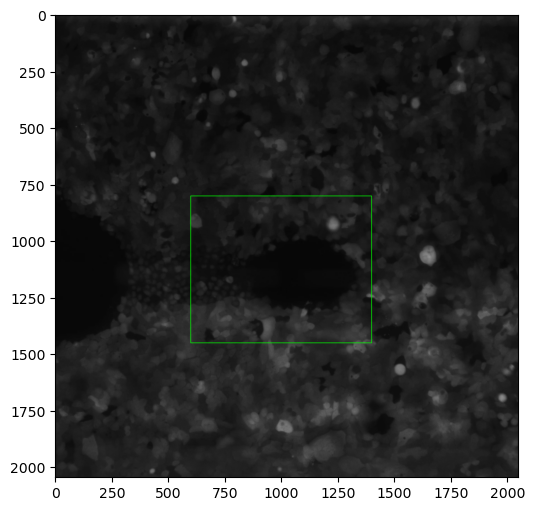

In [12]:
# Enter cell size (USER INPUT HERE)
# Measure cell diameter (in pixels) through Image J or something and enter it here
cell_size = 25

# Define size of square to crop (USER INPUT HERE)
# x and y are the co-ordinates of the top left square of the rectangle (in pixels), and w and h are the width and height of the rectangle
x, y, w, h =  600, 800, 800, 650

# Upload the first video from the list (for reference) and save it to a dataframe.
# Code will automatically get number of frames, height and width
df, num_frames, height, width = upload_video(video_names[0])

# Creates a 2D image of the first frame of the video (originally 1D) and converts to grayscale (for code compatibility)
# This image will be used to visualize the rectangle shape and size to crop
pick_contour = cv.cvtColor(df[100].values.reshape(height, width), cv.COLOR_GRAY2BGR)

# USER INPUT HERE
# Allows you to check that the selected rectangle encircles the confinement footprint (change x, y, w, and h as needed)
cv.rectangle(pick_contour, (x,y), (x+w,y+h), (0, 255, 0), 2)
            
# show the output image
fig, ax = plt.subplots(figsize=(6, 6))  
ax.imshow(pick_contour)

In [13]:
# Cycles through each video provided and calls upon functions to upload video, crop video, calculate "pixel" brightness over time, 
# and save these to output excel files. Will countdown through each video as it processes it. Once complete, will print "Done".

for filename in video_names:
    df, num_frames, height, width = upload_video(filename)
    print("Uploaded", filename)
    
    cropped_df, cropped_h, cropped_w = crop(x, y, w, h, df, cell_size)
    print("Cropped")
    
    brightness_over_time = pixel_avg(cropped_df, cell_size, cropped_h, cropped_w)
    print("Averaged")
    
    save_file(brightness_over_time, home_dir, output_subdir, filename, data_extension)

final_height = h / cell_size
final_width = w / cell_size
    
print("Final Height:", final_height)
print("Final Width:", final_width)
print("Done")

Frames: 755
Height: 2044
Width: 2048
Uploaded 20240717_fib_(5)
Cropped
755 754 753 752 751 750 749 748 747 746 745 744 743 742 741 740 739 738 737 736 735 734 733 732 731 730 729 728 727 726 725 724 723 722 721 720 719 718 717 716 715 714 713 712 711 710 709 708 707 706 705 704 703 702 701 700 699 698 697 696 695 694 693 692 691 690 689 688 687 686 685 684 683 682 681 680 679 678 677 676 675 674 673 672 671 670 669 668 667 666 665 664 663 662 661 660 659 658 657 656 655 654 653 652 651 650 649 648 647 646 645 644 643 642 641 640 639 638 637 636 635 634 633 632 631 630 629 628 627 626 625 624 623 622 621 620 619 618 617 616 615 614 613 612 611 610 609 608 607 606 605 604 603 602 601 600 599 598 597 596 595 594 593 592 591 590 589 588 587 586 585 584 583 582 581 580 579 578 577 576 575 574 573 572 571 570 569 568 567 566 565 564 563 562 561 560 559 558 557 556 555 554 553 552 551 550 549 548 547 546 545 544 543 542 541 540 539 538 537 536 535 534 533 532 531 530 529 528 527 526 525 524 5